In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import wordcloud
from textblob import TextBlob
# from tensorflow.keras.preprocessing.text import Tokenizer
from nltk.sentiment.util import *
import jenkspy
nltk.download('stopwords')
nltk.download('wordnet')
lm = WordNetLemmatizer()

    

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/ghazalehzehtab/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/ghazalehzehtab/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [3]:
biden_tweets = pd.read_csv('Data/biden_df_civility_lables.csv')
biden_tweets

,user_id,likes,retweet_count,cleantext,class
0,1.932939e+07,73.0,4.0,joebiden enlisting list star power help close ...,2
1,1.932939e+07,226.0,14.0,celebs excited america voted blue congrats pre...,2
2,1.716932e+07,717.0,55.0,campaigning across battleground state ran grea...,2
3,2.158642e+07,22641.0,2543.0,big fight today realdonaldtrump v joebiden got...,2
4,1.191236e+07,6748.0,919.0,news outlet projected joebiden secured elector...,2
...,...,...,...,...,...
179570,1.325025e+18,0.0,0.0,joebiden uselectionresults kamalaharris http c...,1
179571,1.322222e+18,0.0,0.0,price tea china go biden get elected,2
179572,1.318598e+18,0.0,0.0,electric vehicle made lamborghini porsche bent...,2
179573,1.199519e+18,0.0,0.0,realdonaldtrump like monopoly joebiden skip ja...,1


In [7]:
def user_activity(dataframe):
    tweet_counts = dataframe.groupby('user_id').size()
    labels = tweet_counts.apply(lambda x: 'active' if x > 5 else 'less active')
    dataframe['user_activity'] = dataframe['user_id'].map(labels)
    return dataframe

def getsubjectivity(text):
    return TextBlob(text).sentiment.subjectivity
def getpolarity(text):
    return TextBlob(text).sentiment.polarity
def getAnalysis(score):
    if score <0:
        return 'negative'
    elif score == 0:
        return 'neutral'
    else:
        return 'positive'
def sentiment_analysis(tweets):
    tweets['subjectivity'] = tweets['cleantext'].apply(getsubjectivity)
    
    tweets['polarity'] = tweets['cleantext'].apply(getpolarity)
    
    tweets['analysis'] = tweets['polarity'].apply(getAnalysis)
    return tweets
def check_and_convert(value):
    if isinstance(value, float):  # Check if the value is a float
        return str(value)         # Convert float to string
    else:
        return value              # Return value unchanged if not a float


biden_tweets_activity = user_activity(biden_tweets)

In [8]:
biden_tweets_activity[biden_tweets_activity['user_activity'] == 'active'].head()

,user_id,likes,retweet_count,cleantext,class,user_activity
7,17446621.0,406.0,40.0,victory speech joebiden said understood trump ...,2,active
8,17446621.0,272.0,18.0,gabrielleunion reacted news joebiden taken lea...,2,active
9,17446621.0,515.0,38.0,hollywood star cheer joebiden take lead pennsy...,2,active
10,17446621.0,186.0,15.0,gabrielle union kerry washington eva longoria ...,2,active
11,17446621.0,73.0,1.0,jimmykimmel offered view last day gone close r...,2,active


In [6]:
print("Biden active user",biden_tweets_activity[biden_tweets_activity['user_activity'] == 'active'].shape)
print("Biden less active user",biden_tweets_activity[biden_tweets_activity['user_activity'] == 'less active'].shape)

Biden active user (96705, 6)
Biden less active user (82870, 6)


In [9]:
biden_df = sentiment_analysis(biden_tweets_activity)
biden_df.head()

,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis
0,19329393.0,73.0,4.0,joebiden enlisting list star power help close ...,2,less active,0.0000,0.00000,neutral
1,19329393.0,226.0,14.0,celebs excited america voted blue congrats pre...,2,less active,0.6625,0.49375,positive
2,17169320.0,717.0,55.0,campaigning across battleground state ran grea...,2,less active,0.7500,0.80000,positive
3,21586418.0,22641.0,2543.0,big fight today realdonaldtrump v joebiden got...,2,less active,0.1000,0.00000,neutral
4,11912362.0,6748.0,919.0,news outlet projected joebiden secured elector...,2,less active,0.0000,0.00000,neutral


In [10]:
sorted_biden = biden_df.sort_values(by=['likes', 'retweet_count'], ascending=False)
sorted_biden.head()

,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis
102,139823781.0,165702.0,17652.0,tonight woman audience trump town hall began q...,2,active,0.5125,0.483333,positive
19865,38362690.0,74528.0,20615.0,america assembled joebiden kamalaharris barack...,2,less active,0.0000,0.000000,neutral
94,139823781.0,59403.0,7489.0,god bette scared god fascist whitehouse racist...,1,active,0.4500,0.080000,positive
90,139823781.0,59345.0,2838.0,wonderful speech tonight president vice presid...,2,active,0.6800,0.522500,positive
92,139823781.0,45540.0,6133.0,god bette scared fascist whitehouse racist cri...,1,active,0.5625,0.100000,positive


In [11]:
biden_df.analysis.value_counts()

analysis
neutral     83859
positive    65654
negative    30062
Name: count, dtype: int64

In [12]:
biden_df['class'].value_counts()

class
2    132172
1     47389
0        14
Name: count, dtype: int64

In [15]:
num_bins = 5

breaks = jenkspy.jenks_breaks(sorted_biden['likes'], n_classes= num_bins)
print(breaks)
sorted_biden['likes_category'] = pd.cut(sorted_biden['likes'], bins=breaks, labels=range(1, num_bins+1), include_lowest=True)
sorted_biden.head(1000)

[0.0, 1498.0, 8855.0, 28696.0, 74528.0, 165702.0]


,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis,likes_category
102,1.398238e+08,165702.0,17652.0,tonight woman audience trump town hall began q...,2,active,0.512500,0.483333,positive,5
19865,3.836269e+07,74528.0,20615.0,america assembled joebiden kamalaharris barack...,2,less active,0.000000,0.000000,neutral,4
94,1.398238e+08,59403.0,7489.0,god bette scared god fascist whitehouse racist...,1,active,0.450000,0.080000,positive,4
90,1.398238e+08,59345.0,2838.0,wonderful speech tonight president vice presid...,2,active,0.680000,0.522500,positive,4
92,1.398238e+08,45540.0,6133.0,god bette scared fascist whitehouse racist cri...,1,active,0.562500,0.100000,positive,4
...,...,...,...,...,...,...,...,...,...,...
756,2.858792e+07,278.0,81.0,people think voting guy vote decency election ...,2,active,0.000000,0.000000,neutral,1
2640,4.439796e+07,278.0,64.0,joebiden celebrated abc right donaldtrump inte...,1,active,0.642857,0.317857,positive,1
12291,2.095488e+07,278.0,54.0,breaking joebiden take lead georgia vote trump...,2,active,0.650000,0.400000,positive,1
676,1.899340e+07,278.0,35.0,breaking abc news characterize joe biden appar...,2,active,0.412500,0.412500,positive,1


In [16]:
breaks = jenkspy.jenks_breaks(sorted_biden['retweet_count'], n_classes= num_bins)
print(breaks)
sorted_biden['retweet_count_category'] = pd.cut(sorted_biden['retweet_count'], bins=breaks, labels=range(1, num_bins+1), include_lowest=True)
sorted_biden.head(1000)

[0.0, 209.0, 1072.0, 2999.0, 7489.0, 20615.0]


,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis,likes_category,retweet_count_category
102,1.398238e+08,165702.0,17652.0,tonight woman audience trump town hall began q...,2,active,0.512500,0.483333,positive,5,5
19865,3.836269e+07,74528.0,20615.0,america assembled joebiden kamalaharris barack...,2,less active,0.000000,0.000000,neutral,4,5
94,1.398238e+08,59403.0,7489.0,god bette scared god fascist whitehouse racist...,1,active,0.450000,0.080000,positive,4,4
90,1.398238e+08,59345.0,2838.0,wonderful speech tonight president vice presid...,2,active,0.680000,0.522500,positive,4,3
92,1.398238e+08,45540.0,6133.0,god bette scared fascist whitehouse racist cri...,1,active,0.562500,0.100000,positive,4,4
...,...,...,...,...,...,...,...,...,...,...,...
756,2.858792e+07,278.0,81.0,people think voting guy vote decency election ...,2,active,0.000000,0.000000,neutral,1,1
2640,4.439796e+07,278.0,64.0,joebiden celebrated abc right donaldtrump inte...,1,active,0.642857,0.317857,positive,1,1
12291,2.095488e+07,278.0,54.0,breaking joebiden take lead georgia vote trump...,2,active,0.650000,0.400000,positive,1,1
676,1.899340e+07,278.0,35.0,breaking abc news characterize joe biden appar...,2,active,0.412500,0.412500,positive,1,1


In [17]:
sorted_biden.to_csv('sorted_biden_categorical_civility.csv', index=False)

In [18]:
sorted_biden.groupby('retweet_count_category')['polarity'].mean()

/var/folders/x5/k2wknhr57b1bk7btjrfpvfbm0000gn/T/ipykernel_24485/3844585572.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sorted_biden.groupby('retweet_count_category')['polarity'].mean()


retweet_count_category
1    0.080197
2    0.088360
3    0.172905
4    0.131111
5    0.241667
Name: polarity, dtype: float64

In [19]:
sorted_biden.retweet_count_category.value_counts()

retweet_count_category
1    179183
2       349
3        32
4         9
5         2
Name: count, dtype: int64

In [20]:
sorted_biden.likes_category.value_counts()

likes_category
1    179401
2       152
3        16
4         5
5         1
Name: count, dtype: int64

In [ ]:
sorted_biden.user_id.value_counts()

In [21]:
grouped_biden = sorted_biden.groupby(['user_id', 'analysis']).size().unstack(fill_value=0)
grouped_biden['Total_tweets'] = grouped_biden['positive'] + grouped_biden['negative']+grouped_biden['neutral']
grouped_biden ['user_polarization'] = ((grouped_biden['positive']-grouped_biden['negative']) * (
            grouped_biden['Total_tweets'] - grouped_biden['neutral'])) / pow(grouped_biden['Total_tweets'],2)
grouped_biden

analysis,negative,neutral,positive,Total_tweets,user_polarization
user_id,,,,,
1.081000e+03,0,1,0,1,0.00
2.654000e+03,0,1,4,5,0.64
3.652000e+03,0,1,0,1,0.00
4.358000e+03,0,1,0,1,0.00
5.608000e+03,0,1,0,1,0.00
...,...,...,...,...,...
1.325492e+18,0,1,0,1,0.00
1.325502e+18,0,0,1,1,1.00
1.325533e+18,0,0,1,1,1.00


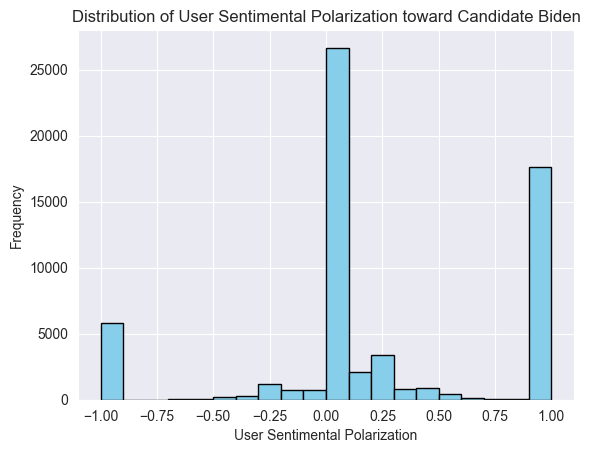

In [22]:
plt.hist(grouped_biden['user_polarization'], bins=20, color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('User Sentimental Polarization')
plt.ylabel('Frequency')
plt.title('Distribution of User Sentimental Polarization toward Candidate Biden')
plt.savefig('user_polarization_distribution.png')
# Show the plot
plt.show()

# Some Civility analysis

In [23]:
sorted_biden.head()

,user_id,likes,retweet_count,cleantext,class,user_activity,subjectivity,polarity,analysis,likes_category,retweet_count_category
102,139823781.0,165702.0,17652.0,tonight woman audience trump town hall began q...,2,active,0.5125,0.483333,positive,5,5
19865,38362690.0,74528.0,20615.0,america assembled joebiden kamalaharris barack...,2,less active,0.0000,0.000000,neutral,4,5
94,139823781.0,59403.0,7489.0,god bette scared god fascist whitehouse racist...,1,active,0.4500,0.080000,positive,4,4
90,139823781.0,59345.0,2838.0,wonderful speech tonight president vice presid...,2,active,0.6800,0.522500,positive,4,3
92,139823781.0,45540.0,6133.0,god bette scared fascist whitehouse racist cri...,1,active,0.5625,0.100000,positive,4,4


In [24]:
sorted_biden.groupby('class')['polarity'].mean()

class
0    0.050247
1    0.046100
2    0.092476
Name: polarity, dtype: float64

In [25]:
sorted_biden.groupby('class')['subjectivity'].mean()

class
0    0.397854
1    0.287198
2    0.306906
Name: subjectivity, dtype: float64

In [30]:
final_biden= sorted_biden.groupby('user_id').agg({'class': 'mean', 'polarity': 'mean', 'likes': 'sum'})


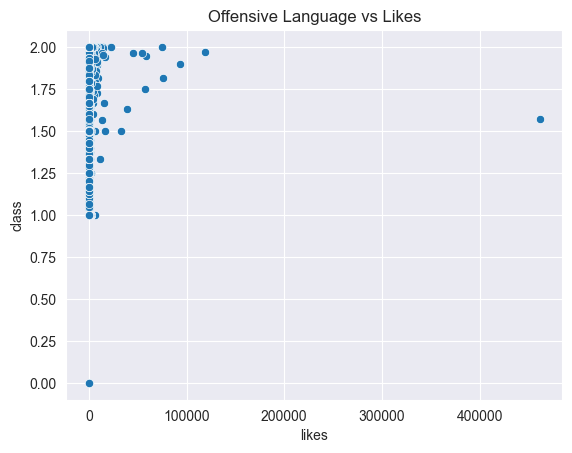

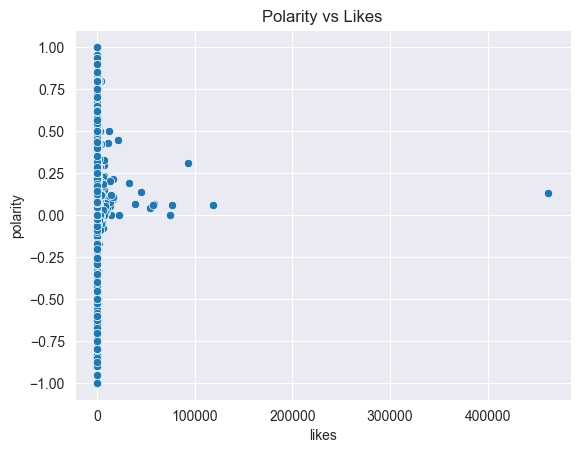

In [54]:
# Scatter plot between offensive language and likes
sns.scatterplot(x='likes', y='class', data=final_biden)
plt.title('Civility vs Likes')
plt.show()

# Scatter plot between polarity and likes
sns.scatterplot(x='likes', y='polarity', data=final_biden)
plt.title('Polarity vs Likes')
plt.show()

In [55]:
final_biden_filtered = final_biden[(final_biden['likes'] > 0.01) & (final_biden['class'] < 1.999) & (final_biden['class'] > 0.001) & (final_biden['likes'] < 400000)]

# Reset index if needed

final_biden_filtered

,class,polarity,likes
user_id,,,
1.081000e+03,1.000000,0.000000,72.0
2.654000e+03,1.800000,0.083333,2.0
1.149300e+04,1.000000,0.700000,1.0
4.369300e+04,1.000000,-0.081250,12.0
6.551300e+04,1.000000,0.100000,384.0
...,...,...,...
1.325229e+18,1.000000,-0.500000,1.0
1.325255e+18,1.500000,0.000000,13.0
1.325260e+18,1.000000,0.000000,1.0


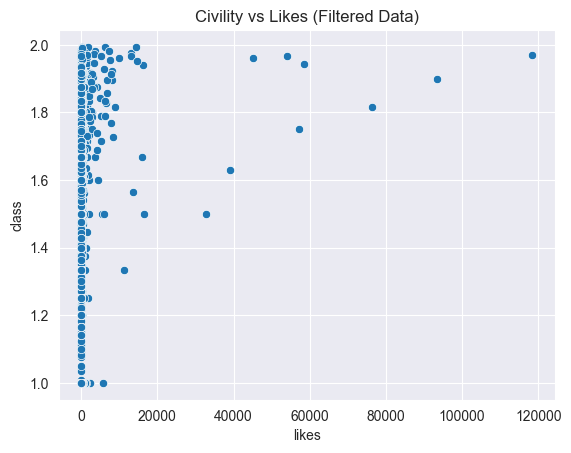

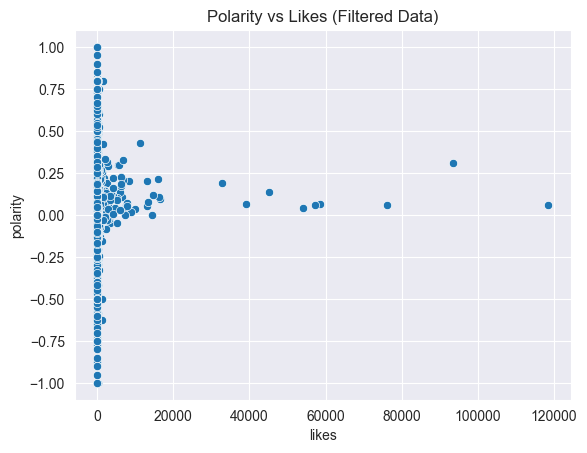

In [57]:

sns.scatterplot(x='likes', y='class', data=final_biden_filtered)
plt.title('Civility vs Likes (Filtered Data)')
plt.show()

# Scatter plot between polarity and likes
sns.scatterplot(x='likes', y='polarity', data=final_biden_filtered)
plt.title('Polarity vs Likes (Filtered Data)')
plt.show()

